# Transformer From Scratch — the classroom walkthrough

**6 encoder layers + 6 decoder layers, 8 attention heads**, built from bare PyTorch
(`nn.Linear`, `nn.LayerNorm`, `softmax` — no `nn.Transformer`, no pretrained model,
no API key, no internet).

Task: **English → French** translation from **73 sentence pairs** — 67 for training,
6 held back and never trained on.

> Accuracy is not the point. The point is that you can *see* every box from the
> architecture diagram as a real tensor with a real shape, and then watch the loss
> turn random numbers into French.

Runs on a laptop CPU. Training takes about **30 seconds**.

| # | Section | What you see |
|---|---------|--------------|
| 0 | Setup | the paper's hyperparameters, shrunk |
| 1 | Data & tokenizer | words → integer ids, and teacher forcing |
| 2 | Embeddings + positional encoding | ids → vectors, and how order gets injected |
| 3 | Scaled dot-product attention | the one formula, on a 3-token toy |
| 4 | Multi-head attention | 8 opinions by reshaping, not by 8 matrices |
| 5 | The two masks | padding, and "no peeking at the future" |
| 6 | Feed-forward, residual, LayerNorm | the other two-thirds of every layer |
| 7 | One encoder layer / one decoder layer | where cross-attention lives |
| 8 | The full model | 6 + 6 stacked, ~510k parameters |
| 9 | Shape tour | one sentence, every tensor shape, in order |
| 10 | Greedy decoding | the loop ChatGPT runs to stream tokens |
| 11 | **BEFORE** training | complete architecture, random weights, nonsense out |
| 12 | Attention before training | flat, featureless heat maps |
| 13 | **Training** | the epoch loop, train loss vs held-out loss |
| 14 | **Reading the loss curve** | five phases, and where overfitting starts |
| 15 | **AFTER** training | same code, different numbers |
| 16 | Generalisation | 5 of 6 unseen sentences right — and *why* the 6th is wrong |
| 17 | Embeddings | where the meaning ended up |
| 18 | Try it yourself | take sentences from the room |
| 19 | Live experiments | break one thing, see what dies |

## 0. Setup and hyperparameters

Every knob lives in this one cell — which makes the experiments in section 19 easy.

These are the paper's hyperparameters, only smaller. `d_model` must divide evenly by
`n_heads` — that is the only hard rule.

> 🎤 **Say this in class:** The original paper used d_model=512 and d_ff=2048. We use 64 and 128 so the numbers stay readable on a projector. Nothing else changes.

In [ ]:
!pip install torch matplotlib

In [2]:
import math
import time
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
%matplotlib inline

N_LAYERS   = 6      # 6 encoder layers AND 6 decoder layers   (as in the paper)
N_HEADS    = 8      # 8 attention heads                       (as in the paper)
D_MODEL    = 64     # embedding size. Paper uses 512; we shrink it to stay readable
D_FF       = 128    # hidden width of the feed-forward block  (paper: 2048)
DROPOUT    = 0.1
EPOCHS     = 1500   # full-batch steps. ~40 seconds on a CPU
LR         = 1e-3

# When to stop and score the held-out set. Dense at the start, because almost
# everything interesting happens in the first 60 epochs.
CHECKPOINTS = ([1, 2, 3, 5, 8, 11, 15, 20, 26, 33, 40, 50, 65, 80, 100, 125, 150]
               + list(range(200, 1501, 100)))

D_HEAD = D_MODEL // N_HEADS          # 64 / 8 = 8 dimensions per head

print(f"torch {torch.__version__}")
print(f"{N_LAYERS} encoders + {N_LAYERS} decoders | "
      f"{N_HEADS} heads x {D_HEAD} dims = {D_MODEL} d_model")

torch 2.6.0
6 encoders + 6 decoders | 8 heads x 8 dims = 64 d_model


## 1. The data and the tokenizer

**73 pairs**, deliberately *compositional*: subjects × verbs × objects. That lets the
model learn reusable pieces (`i → je`, `the cat → le chat`, `he likes → il aime`)
instead of memorising whole sentences.

**6 pairs are held out** and never trained on. Every word in them appears somewhere in
training — only the *combination* is new. That is what we will measure at the end.

French is written without apostrophes (`j aime`, `l eau`) because our tokenizer splits
on spaces. Real systems use sub-word BPE / SentencePiece, which handles this properly.

Three special tokens do real work:
- `<pad>` (id 0) — filler so all sentences in a batch have equal length
- `<sos>` — the decoder's "start writing" signal
- `<eos>` — the decoder's "I'm done" signal

> 🎤 **Say this in class:** A transformer never sees letters or words. It sees integers. Everything after this cell is arithmetic on numbers, not language.

In [3]:
TRAIN_PAIRS = [
    # --- "to be" + profession ----------------------------------------------
    ("i am a student",      "je suis un etudiant"),
    ("i am a teacher",      "je suis un professeur"),
    ("you are a student",   "tu es un etudiant"),
    ("you are a teacher",   "tu es un professeur"),
    ("he is a student",     "il est un etudiant"),
    ("he is a teacher",     "il est un professeur"),
    ("she is a student",    "elle est un etudiant"),
    ("she is a teacher",    "elle est un professeur"),
    # --- "to be" + adjective (note the feminine agreement on 'she') --------
    ("i am happy",          "je suis content"),
    ("you are happy",       "tu es content"),
    ("he is happy",         "il est content"),
    ("she is happy",        "elle est contente"),
    ("i am tired",          "je suis fatigue"),
    ("you are tired",       "tu es fatigue"),
    ("he is tired",         "il est fatigue"),
    ("she is tired",        "elle est fatiguee"),
    ("i am ready",          "je suis pret"),
    ("you are ready",       "tu es pret"),
    ("he is ready",         "il est pret"),
    # --- "to like" + object -------------------------------------------------
    ("i like the book",     "j aime le livre"),
    ("i like the cat",      "j aime le chat"),
    ("i like the dog",      "j aime le chien"),
    ("i like the car",      "j aime la voiture"),
    ("i like music",        "j aime la musique"),
    ("i like coffee",       "j aime le cafe"),
    ("i like tea",          "j aime le the"),
    ("you like the book",   "tu aimes le livre"),
    ("you like the cat",    "tu aimes le chat"),
    ("you like the dog",    "tu aimes le chien"),
    ("you like the car",    "tu aimes la voiture"),
    ("you like music",      "tu aimes la musique"),
    ("you like tea",        "tu aimes le the"),
    ("he likes the book",   "il aime le livre"),
    ("he likes the cat",    "il aime le chat"),
    ("he likes the dog",    "il aime le chien"),
    ("he likes music",      "il aime la musique"),
    ("he likes coffee",     "il aime le cafe"),
    ("she likes the book",  "elle aime le livre"),
    ("she likes the cat",   "elle aime le chat"),
    ("she likes the dog",   "elle aime le chien"),
    ("she likes music",     "elle aime la musique"),
    ("she likes coffee",    "elle aime le cafe"),
    # --- "to have" ----------------------------------------------------------
    ("i have a book",       "j ai un livre"),
    ("i have a car",        "j ai une voiture"),
    ("i have a dog",        "j ai un chien"),
    ("i have a cat",        "j ai un chat"),
    ("you have a book",     "tu as un livre"),
    ("you have a car",      "tu as une voiture"),
    ("you have a dog",      "tu as un chien"),
    ("he has a book",       "il a un livre"),
    ("he has a car",        "il a une voiture"),
    ("he has a cat",        "il a un chat"),
    ("she has a book",      "elle a un livre"),
    ("she has a car",       "elle a une voiture"),
    # --- eat / drink / read -------------------------------------------------
    ("i eat the apple",     "je mange la pomme"),
    ("you eat the apple",   "tu manges la pomme"),
    ("he eats the apple",   "il mange la pomme"),
    ("i eat the bread",     "je mange le pain"),
    ("you eat the bread",   "tu manges le pain"),
    ("i drink the water",   "je bois l eau"),
    ("he drinks the water", "il boit l eau"),
    ("i read the book",     "je lis le livre"),
    ("you read the book",   "tu lis le livre"),
    ("he reads the book",   "il lit le livre"),
    ("she reads the book",  "elle lit le livre"),
    # --- noun subjects ------------------------------------------------------
    ("the cat is happy",    "le chat est content"),
    ("the dog is tired",    "le chien est fatigue"),
]

# NEVER trained on. Every word below appears in TRAIN_PAIRS -- only the
# combination is new. This is our test set.
HELD_OUT = [
    ("she likes tea",       "elle aime le the"),
    ("he has a dog",        "il a un chien"),
    ("she eats the apple",  "elle mange la pomme"),
    ("you like coffee",     "tu aimes le cafe"),
    ("the cat is tired",    "le chat est fatigue"),
    ("you drink the water", "tu bois l eau"),
]

PAD, SOS, EOS = "<pad>", "<sos>", "<eos>"


def build_vocab(sentences):
    """Word-level vocabulary. Real systems use sub-word BPE / SentencePiece."""
    words = sorted({w for s in sentences for w in s.split()})
    itos = [PAD, SOS, EOS] + words                  # index -> string
    stoi = {w: i for i, w in enumerate(itos)}       # string -> index
    return stoi, itos


# Vocabulary is built over BOTH splits -- otherwise a held-out word would have
# no row in the embedding table at all and the test would be unfair.
ALL = TRAIN_PAIRS + HELD_OUT
SRC_STOI, SRC_ITOS = build_vocab([p[0] for p in ALL])
TGT_STOI, TGT_ITOS = build_vocab([p[1] for p in ALL])


def encode(sentence, stoi, add_sos_eos=False):
    ids = [stoi[w] for w in sentence.split()]
    if add_sos_eos:
        ids = [stoi[SOS]] + ids + [stoi[EOS]]
    return ids


print(f"{len(TRAIN_PAIRS)} training pairs + {len(HELD_OUT)} held-out pairs "
      f"= {len(ALL)} sentences")
print()
print(f"English vocab ({len(SRC_ITOS)}):", SRC_ITOS)
print()
print(f"French  vocab ({len(TGT_ITOS)}):", TGT_ITOS)
print()
print("'he likes the cat'  ->", encode("he likes the cat", SRC_STOI))
print("'il aime le chat'   ->", encode("il aime le chat", TGT_STOI, add_sos_eos=True),
      " (with <sos>/<eos>)")

67 training pairs + 6 held-out pairs = 73 sentences

English vocab (37): ['<pad>', '<sos>', '<eos>', 'a', 'am', 'apple', 'are', 'book', 'bread', 'car', 'cat', 'coffee', 'dog', 'drink', 'drinks', 'eat', 'eats', 'happy', 'has', 'have', 'he', 'i', 'is', 'like', 'likes', 'music', 'read', 'reads', 'ready', 'she', 'student', 'tea', 'teacher', 'the', 'tired', 'water', 'you']

French  vocab (44): ['<pad>', '<sos>', '<eos>', 'a', 'ai', 'aime', 'aimes', 'as', 'bois', 'boit', 'cafe', 'chat', 'chien', 'content', 'contente', 'eau', 'elle', 'es', 'est', 'etudiant', 'fatigue', 'fatiguee', 'il', 'j', 'je', 'l', 'la', 'le', 'lis', 'lit', 'livre', 'mange', 'manges', 'musique', 'pain', 'pomme', 'pret', 'professeur', 'suis', 'the', 'tu', 'un', 'une', 'voiture']

'he likes the cat'  -> [20, 24, 33, 10]
'il aime le chat'   -> [1, 22, 5, 27, 11, 2]  (with <sos>/<eos>)


### Teacher forcing — the decoder's training trick

During training we do **not** let the model generate word by word. We feed it the
correct answer shifted right, and ask it to predict the answer shifted left:

```
decoder INPUT : <sos>  je   suis  un   etudiant
decoder TARGET:  je   suis   un  etudiant  <eos>
```

So every position is trained in parallel — that is why transformers train so much
faster than RNNs, which had to walk the sentence one step at a time.

> 🎤 **Say this in class:** The decoder is trained to predict the NEXT word given the correct words so far. Because we feed the whole correct sentence at once, all positions train in parallel. This single trick is why transformers scale and RNNs did not.

In [4]:
def make_batch(pairs):
    """Pad everything to a rectangle, then build the shifted decoder tensors."""
    src = [encode(s, SRC_STOI) for s, _ in pairs]
    tgt = [encode(t, TGT_STOI, add_sos_eos=True) for _, t in pairs]
    smax, tmax = max(map(len, src)), max(map(len, tgt))
    src = [s + [0] * (smax - len(s)) for s in src]      # 0 == <pad>
    tgt = [t + [0] * (tmax - len(t)) for t in tgt]
    src, tgt = torch.tensor(src), torch.tensor(tgt)
    return src, tgt[:, :-1], tgt[:, 1:]                 # src, tgt_in, tgt_out


src, tgt_in, tgt_out = make_batch(TRAIN_PAIRS)
print("src      ", tuple(src.shape),     "(batch, src_len)")
print("tgt_in   ", tuple(tgt_in.shape),  "(batch, tgt_len)")
print("tgt_out  ", tuple(tgt_out.shape))
print()
print("row 0 tgt_in :", [TGT_ITOS[i] for i in tgt_in[0].tolist()])
print("row 0 tgt_out:", [TGT_ITOS[i] for i in tgt_out[0].tolist()])
print()
print("Read those two rows together: at every position, the target is the input")
print("shifted one step left. <pad> at the end is ignored by the loss.")

src       (67, 4) (batch, src_len)
tgt_in    (67, 5) (batch, tgt_len)
tgt_out   (67, 5)

row 0 tgt_in : ['<sos>', 'je', 'suis', 'un', 'etudiant']
row 0 tgt_out: ['je', 'suis', 'un', 'etudiant', '<eos>']

Read those two rows together: at every position, the target is the input
shifted one step left. <pad> at the end is ignored by the loss.


## 2. Embeddings + positional encoding

`nn.Embedding` is just a lookup table: **word id → a learnable 64-dim vector**.
Those numbers start random and are trained like any other weight.

But attention sees a *set*, not a sequence — swap two words and the maths is
identical. So we **add** a fixed sine/cosine pattern that differs by position:

$$PE_{(pos,2i)}=\sin\!\Big(\frac{pos}{10000^{2i/d}}\Big)\qquad
PE_{(pos,2i+1)}=\cos\!\Big(\frac{pos}{10000^{2i/d}}\Big)$$

Each position gets a unique fingerprint, and nearby positions get similar ones.

> 🎤 **Say this in class:** Two things are added together here: WHAT the word is (embedding) and WHERE it sits (positional encoding). Same vector space, same 64 numbers. It feels like it should corrupt the meaning - it does not, because the network learns to read both out again.

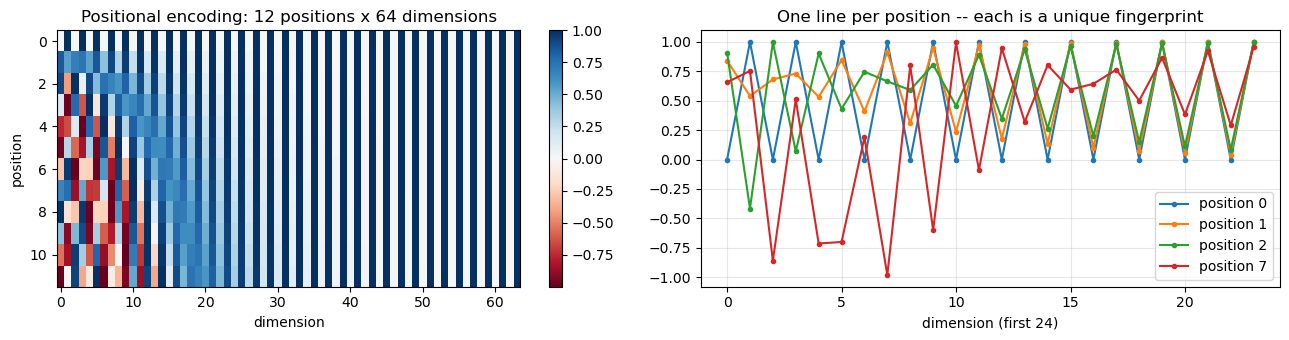

Positions 0 and 1 look similar; positions 0 and 7 do not.
That similarity is what lets the model reason about 'nearby'.


In [5]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=50):
        super().__init__()
        pe  = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()                 # (max_len, 1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)      # even dimensions -> sine
        pe[:, 1::2] = torch.cos(pos * div)      # odd  dimensions -> cosine
        self.register_buffer("pe", pe.unsqueeze(0))                      # (1, max_len, d_model)

    def forward(self, x):                       # x: (batch, seq, d_model)
        return x + self.pe[:, : x.size(1)]


# ---- look at the pattern itself ---------------------------------------------
pe_demo = PositionalEncoding(D_MODEL)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
im = ax[0].imshow(pe_demo.pe[0, :12].numpy(), aspect="auto", cmap="RdBu")
ax[0].set(title="Positional encoding: 12 positions x 64 dimensions",
          xlabel="dimension", ylabel="position")
plt.colorbar(im, ax=ax[0])
for p in [0, 1, 2, 7]:
    ax[1].plot(pe_demo.pe[0, p, :24].numpy(), marker="o", ms=3, label=f"position {p}")
ax[1].set(title="One line per position -- each is a unique fingerprint",
          xlabel="dimension (first 24)")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Positions 0 and 1 look similar; positions 0 and 7 do not.")
print("That similarity is what lets the model reason about 'nearby'.")

## 3. Scaled dot-product attention — the heart of it

$$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_k}}\right)V$$

Read it as a soft lookup table:

| | comes from | intuition |
|---|---|---|
| **Q** query | the token doing the looking | *"what am I looking for?"* |
| **K** key   | every token that can be looked at | *"what do I advertise?"* |
| **V** value | every token that can be looked at | *"what do I hand over if picked?"* |

1. `Q @ Kᵀ` — score every token against every token (a T×T grid)
2. `/ √d_k` — without this, dot products of 64-dim vectors get large, softmax saturates and gradients die
3. `softmax` — turn each row into weights that sum to 1
4. `@ V` — each token's output is a weighted blend of everyone's value vector

> 🎤 **Say this in class:** This is the whole idea. A dictionary lookup is hard - one key matches. Attention is soft - every key matches a little, and softmax decides how much.

In [6]:
def attention(Q, K, V, mask=None):
    # Q, K, V : (batch, heads, seq, d_head)
    d_k = Q.size(-1)
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d_k)     # (batch, heads, Tq, Tk)
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))   # blocked -> ~0 after softmax
    weights = torch.softmax(scores, dim=-1)               # every row sums to 1.0
    return weights @ V, weights


# ---- a 3-token toy example, small enough to read by eye ----------------------
torch.manual_seed(1)
Q = K = V = torch.randn(1, 1, 3, 4)          # batch 1, head 1, 3 tokens, 4 dims
out, w = attention(Q, K, V)
print("Q shape", tuple(Q.shape), " scores/weights shape", tuple(w.shape))
print("\nattention weights (row = token doing the looking):")
print(w[0, 0].round(decimals=2))
print("\nrow sums:", w[0, 0].sum(-1).round(decimals=3), " <- softmax guarantees this")
print("output   ", tuple(out.shape), "= same shape as V, but each row is now a blend")

# ---- why the sqrt(d_k) matters ----------------------------------------------
print("\n--- what happens WITHOUT the /sqrt(d_k) ---")
big_q = torch.randn(1, 1, 3, 64)
big_k = torch.randn(1, 1, 3, 64)
raw = (big_q @ big_k.transpose(-2, -1))
print("raw scores (64 dims)     :", raw[0, 0, 0].round(decimals=1).tolist())
print("softmax of raw           :", torch.softmax(raw, -1)[0, 0, 0].round(decimals=3).tolist())
print("softmax of raw/sqrt(64)  :", torch.softmax(raw / 8, -1)[0, 0, 0].round(decimals=3).tolist())
print("Unscaled, softmax collapses to one-hot -> gradients vanish -> no learning.")

Q shape (1, 1, 3, 4)  scores/weights shape (1, 1, 3, 3)

attention weights (row = token doing the looking):
tensor([[0.5100, 0.2900, 0.2000],
        [0.1200, 0.5300, 0.3500],
        [0.1000, 0.4200, 0.4800]])

row sums: tensor([1., 1., 1.])  <- softmax guarantees this
output    (1, 1, 3, 4) = same shape as V, but each row is now a blend

--- what happens WITHOUT the /sqrt(d_k) ---
raw scores (64 dims)     : [-5.400000095367432, 7.300000190734863, 12.399999618530273]
softmax of raw           : [0.0, 0.006000000052154064, 0.9940000176429749]
softmax of raw/sqrt(64)  : [0.06599999964237213, 0.32199999690055847, 0.6119999885559082]
Unscaled, softmax collapses to one-hot -> gradients vanish -> no learning.


## 4. Multi-head attention — 8 opinions instead of 1

One attention pass gives one way of relating words. The paper runs **8 in parallel**,
each in its own 8-dimensional subspace, then concatenates them.

The implementation trick: don't build 8 small matrices. Build one `64 → 64` Linear
and **reshape**:

```
(batch, seq, 64)  --view+transpose-->  (batch, 8, seq, 8)
                                              ↑heads   ↑d_head
```

Heads specialise on their own — one may track the subject, another the object.
We stash the weights in `self.last_weights` so we can plot them later.

> 🎤 **Say this in class:** Ask the class: why 8 heads instead of 1 big one? Because one softmax can only focus on one pattern at a time. Eight heads let the layer attend to the subject AND the verb AND the object in the same pass.

In [7]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.h, self.d_head = n_heads, d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model)   # <-- the Q matrix
        self.W_k = nn.Linear(d_model, d_model)   # <-- the K matrix
        self.W_v = nn.Linear(d_model, d_model)   # <-- the V matrix
        self.W_o = nn.Linear(d_model, d_model)   # merges the heads back together
        self.last_weights = None                 # saved for the heat maps

    def split_heads(self, x):                    # (B, T, 64) -> (B, 8, T, 8)
        B, T, _ = x.shape
        return x.view(B, T, self.h, self.d_head).transpose(1, 2)

    def forward(self, q_in, k_in, v_in, mask=None):
        Q = self.split_heads(self.W_q(q_in))
        K = self.split_heads(self.W_k(k_in))
        V = self.split_heads(self.W_v(v_in))
        out, w = attention(Q, K, V, mask)
        self.last_weights = w.detach()           # (B, heads, Tq, Tk)
        B, _, T, _ = out.shape
        out = out.transpose(1, 2).contiguous().view(B, T, self.h * self.d_head)  # concat heads
        return self.W_o(out)


mha_demo = MultiHeadAttention(D_MODEL, N_HEADS)
x_demo = torch.randn(1, 5, D_MODEL)              # 1 sentence, 5 tokens
print("input                     ", tuple(x_demo.shape))
print("after W_q                 ", tuple(mha_demo.W_q(x_demo).shape), " still 64 wide")
print("after split_heads         ", tuple(mha_demo.split_heads(mha_demo.W_q(x_demo)).shape),
      f" <- {N_HEADS} heads x {D_HEAD} dims")
print("output                    ", tuple(mha_demo(x_demo, x_demo, x_demo).shape),
      " heads concatenated, back to 64")
print("attention weights stored  ", tuple(mha_demo.last_weights.shape),
      " (batch, heads, Tq, Tk)")
print(f"\nparameters in ONE attention block: "
      f"{sum(p.numel() for p in mha_demo.parameters()):,}  (4 matrices of 64x64 + biases)")

input                      (1, 5, 64)
after W_q                  (1, 5, 64)  still 64 wide
after split_heads          (1, 8, 5, 8)  <- 8 heads x 8 dims


output                     (1, 5, 64)  heads concatenated, back to 64
attention weights stored   (1, 8, 5, 5)  (batch, heads, Tq, Tk)

parameters in ONE attention block: 16,640  (4 matrices of 64x64 + biases)


## 5. The two masks

**Padding mask** — `<pad>` is filler, not language. Blocked everywhere.

**Causal mask** — while writing French word *t*, the decoder may only look at words
`0…t`. Without it the model would read the answer off its own input and learn nothing.
Implemented as a lower-triangular matrix of 1s; blocked cells become `-inf` before
the softmax.

> 🎤 **Say this in class:** The mask is the only reason the decoder cannot cheat. Cover the upper triangle with your hand on the plot - that is literally what -inf does.

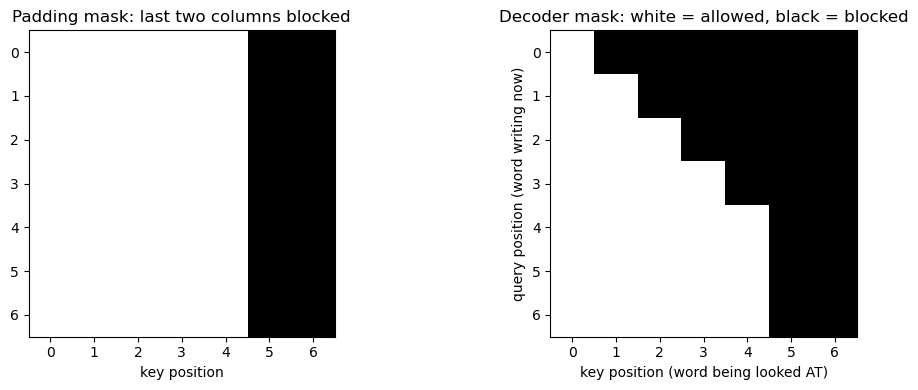

Row 0 may see 1 word. Row 4 may see 5. Nobody sees the two <pad> columns.


In [8]:
def pad_mask(seq):
    """1 where a real token sits, 0 on padding. Shape (B, 1, 1, T)."""
    return (seq != 0).unsqueeze(1).unsqueeze(2)


def causal_mask(seq):
    """Padding mask AND lower-triangular 'no peeking at the future'."""
    T = seq.size(1)
    return pad_mask(seq) & torch.tril(torch.ones(T, T, device=seq.device)).bool()


demo = torch.tensor([[1, 13, 17, 19, 10, 0, 0]])     # last two are <pad>
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(pad_mask(demo)[0, 0].int().repeat(7, 1), cmap="Greys_r")
ax[0].set(title="Padding mask: last two columns blocked", xlabel="key position")
ax[1].imshow(causal_mask(demo)[0, 0].int(), cmap="Greys_r")
ax[1].set(title="Decoder mask: white = allowed, black = blocked",
          xlabel="key position (word being looked AT)",
          ylabel="query position (word writing now)")
plt.tight_layout(); plt.show()

print("Row 0 may see 1 word. Row 4 may see 5. Nobody sees the two <pad> columns.")

## 6. Feed-forward, residual connection, LayerNorm

Attention gets all the attention, but it is only **one third** of a layer. The other
two pieces are what make a 12-layer stack trainable at all:

| Piece | What it does | Why it matters |
|---|---|---|
| **Feed-forward** `64 → 128 → ReLU → 64` | the only non-linearity; applied to each position *independently* | attention **mixes** information across tokens; the FFN **thinks** about it |
| **Residual** `x + sublayer(x)` | a gradient highway straight to the input | without it, 6 stacked layers barely train |
| **LayerNorm** | re-centres and re-scales each token vector | keeps activations in a sane range layer after layer |

How big is each piece? Count them below. Our `d_ff` is only 2× `d_model`, which
splits the layer about **50/50**. The paper uses `d_ff = 4 × d_model` (512 → 2048),
and at that ratio the feed-forward block holds **two-thirds of every layer** — which
is the number real LLMs run at. The cell prints both.

Either way the point stands: the famous part of the transformer is **not** where the
parameters are.

> 🎤 **Say this in class:** Point at the two ratios. At the paper's width, two-thirds of the weights sit in a plain MLP that cannot see other tokens at all. Attention is the cheap part. People always guess the other way round.

In [9]:
class FeedForward(nn.Module):
    """Per-position MLP: 64 -> 128 -> ReLU -> 64.
    Attention MIXES information across tokens; this block THINKS about it."""
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Linear(d_ff, d_model))

    def forward(self, x):
        return self.net(x)


# counted arithmetically, so this cell does not disturb the random seed
attn_params = 4 * (D_MODEL * D_MODEL + D_MODEL)                   # W_q, W_k, W_v, W_o
ff_params   = (D_MODEL * D_FF + D_FF) + (D_FF * D_MODEL + D_MODEL)  # 64->d_ff->64

print(f"OUR config (d_ff = {D_FF} = {D_FF // D_MODEL}x d_model)")
print(f"  attention block : {attn_params:>8,} parameters")
print(f"  feed-forward    : {ff_params:>8,} parameters"
      f"   <- {ff_params / (attn_params + ff_params):.0%} of the layer")

d_ff_paper = 4 * D_MODEL
ff_paper = (D_MODEL * d_ff_paper + d_ff_paper) + (d_ff_paper * D_MODEL + D_MODEL)
print(f"\nPAPER's ratio (d_ff = {d_ff_paper} = 4x d_model)")
print(f"  attention block : {attn_params:>8,} parameters")
print(f"  feed-forward    : {ff_paper:>8,} parameters"
      f"   <- {ff_paper / (attn_params + ff_paper):.0%} of the layer"
      "   <-- the ratio real LLMs use")

# ---- what LayerNorm actually does -------------------------------------------
ln = nn.LayerNorm(D_MODEL)
messy = torch.randn(1, 3, D_MODEL) * 8 + 5          # badly scaled activations
print(f"\nbefore LayerNorm: mean {messy.mean():+.3f}  std {messy.std():.3f}")
normed = ln(messy)
print(f"after  LayerNorm: mean {normed.mean():+.3f}  std {normed.std():.3f}"
      "   <- every token vector, every layer")

OUR config (d_ff = 128 = 2x d_model)
  attention block :   16,640 parameters
  feed-forward    :   16,576 parameters   <- 50% of the layer

PAPER's ratio (d_ff = 256 = 4x d_model)
  attention block :   16,640 parameters
  feed-forward    :   33,088 parameters   <- 67% of the layer   <-- the ratio real LLMs use

before LayerNorm: mean +4.606  std 7.720
after  LayerNorm: mean +0.000  std 1.003   <- every token vector, every layer


## 7. One encoder layer / one decoder layer

**Encoder layer** = self-attention → *add & norm* → feed-forward → *add & norm*

**Decoder layer** = masked self-attention → *add & norm* → **cross-attention** →
*add & norm* → feed-forward → *add & norm*

**Cross-attention is where translation actually happens**: the Query comes from the
French side, the Key and Value come from the encoder's English output. That single
line is the bridge between the two stacks.

> 🎤 **Say this in class:** Three sub-blocks in the decoder vs two in the encoder. The extra one is cross-attention, and it is the single most important line in the notebook: Q from French, K and V from English.

In [10]:
class EncoderLayer(nn.Module):
    def __init__(self):
        super().__init__()
        self.self_attn = MultiHeadAttention(D_MODEL, N_HEADS)
        self.ff = FeedForward(D_MODEL, D_FF)
        self.n1, self.n2 = nn.LayerNorm(D_MODEL), nn.LayerNorm(D_MODEL)
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, x, src_mask):
        x = self.n1(x + self.drop(self.self_attn(x, x, x, src_mask)))   # residual + norm
        x = self.n2(x + self.drop(self.ff(x)))
        return x


class DecoderLayer(nn.Module):
    def __init__(self):
        super().__init__()
        self.self_attn  = MultiHeadAttention(D_MODEL, N_HEADS)
        self.cross_attn = MultiHeadAttention(D_MODEL, N_HEADS)
        self.ff = FeedForward(D_MODEL, D_FF)
        self.n1, self.n2, self.n3 = (nn.LayerNorm(D_MODEL), nn.LayerNorm(D_MODEL),
                                     nn.LayerNorm(D_MODEL))
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, x, enc_out, src_mask, tgt_mask):
        x = self.n1(x + self.drop(self.self_attn(x, x, x, tgt_mask)))          # masked self-attn
        #                   Q from decoder  |  K, V from encoder  <-- THE BRIDGE
        x = self.n2(x + self.drop(self.cross_attn(x, enc_out, enc_out, src_mask)))
        x = self.n3(x + self.drop(self.ff(x)))
        return x


print("EncoderLayer: 2 sub-blocks |", f"{sum(p.numel() for p in EncoderLayer().parameters()):,} params")
print("DecoderLayer: 3 sub-blocks |", f"{sum(p.numel() for p in DecoderLayer().parameters()):,} params")

EncoderLayer: 2 sub-blocks | 33,472 params
DecoderLayer: 3 sub-blocks | 50,240 params


## 8. The full model — 6 encoders + 6 decoders

Stack them, embed both languages, and finish with one `Linear(64 → french_vocab)`
that turns each decoder output vector into a score for every French word.

(`* math.sqrt(D_MODEL)` scales the embeddings up so the positional encoding doesn't
drown them out — a small detail straight from the paper.)

> 🎤 **Say this in class:** Everything so far was one layer. Here we just stack 6 of each and add the output projection. Half a million parameters. GPT-scale models are the same picture - wider, deeper, and trained on the internet instead of 67 sentences.

In [11]:
class Transformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.src_emb  = nn.Embedding(len(SRC_ITOS), D_MODEL)
        self.tgt_emb  = nn.Embedding(len(TGT_ITOS), D_MODEL)
        self.pos      = PositionalEncoding(D_MODEL)
        self.encoders = nn.ModuleList([EncoderLayer() for _ in range(N_LAYERS)])
        self.decoders = nn.ModuleList([DecoderLayer() for _ in range(N_LAYERS)])
        self.out      = nn.Linear(D_MODEL, len(TGT_ITOS))   # project to vocabulary
        self.drop     = nn.Dropout(DROPOUT)

    def encode(self, src):
        x = self.drop(self.pos(self.src_emb(src) * math.sqrt(D_MODEL)))
        m = pad_mask(src)
        for layer in self.encoders:
            x = layer(x, m)
        return x, m                        # this is what every decoder layer reads

    def decode(self, tgt_in, enc_out, src_mask):
        x = self.drop(self.pos(self.tgt_emb(tgt_in) * math.sqrt(D_MODEL)))
        m = causal_mask(tgt_in)
        for layer in self.decoders:
            x = layer(x, enc_out, src_mask, m)
        return x

    def forward(self, src, tgt_in):
        enc_out, src_mask = self.encode(src)
        return self.out(self.decode(tgt_in, enc_out, src_mask))   # logits (B, T, vocab)


model = Transformer()
total = sum(p.numel() for p in model.parameters())
print(f"total parameters: {total:,}")
print(f"  embeddings    : {model.src_emb.weight.numel() + model.tgt_emb.weight.numel():,}")
print(f"  6 encoders    : {sum(p.numel() for p in model.encoders.parameters()):,}")
print(f"  6 decoders    : {sum(p.numel() for p in model.decoders.parameters()):,}")
print(f"  output head   : {sum(p.numel() for p in model.out.parameters()):,}")
print()
print(model.encoders[0])

total parameters: 510,316
  embeddings    : 5,184
  6 encoders    : 200,832
  6 decoders    : 301,440
  output head   : 2,860

EncoderLayer(
  (self_attn): MultiHeadAttention(
    (W_q): Linear(in_features=64, out_features=64, bias=True)
    (W_k): Linear(in_features=64, out_features=64, bias=True)
    (W_v): Linear(in_features=64, out_features=64, bias=True)
    (W_o): Linear(in_features=64, out_features=64, bias=True)
  )
  (ff): FeedForward(
    (net): Sequential(
      (0): Linear(in_features=64, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=64, bias=True)
    )
  )
  (n1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (n2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (drop): Dropout(p=0.1, inplace=False)
)


## 9. Shape tour — follow one sentence through the whole stack

This is the cell to put on the projector **next to the architecture diagram**.
Every arrow in that diagram is one numbered line here.

> 🎤 **Say this in class:** Put this output side by side with the architecture diagram on the slide. Every arrow in the diagram is one numbered line here. Nothing is hidden.

In [12]:
@torch.no_grad()
def shape_tour(model, sentence):
    model.eval()
    ids = encode(sentence, SRC_STOI)
    src = torch.tensor([ids])
    print(f"  1. words                  {sentence.split()}")
    print(f"  2. token ids              {ids}")
    print(f"     src tensor             {tuple(src.shape)}    (batch, seq_len)")

    emb = model.src_emb(src) * math.sqrt(D_MODEL)
    print(f"  3. embeddings             {tuple(emb.shape)}   (batch, seq, d_model={D_MODEL})")
    pos = model.pos(emb)
    print(f"  4. + positional encoding  {tuple(pos.shape)}   same shape, order info added")

    mha = model.encoders[0].self_attn
    Q, K, V = (mha.split_heads(mha.W_q(pos)), mha.split_heads(mha.W_k(pos)),
               mha.split_heads(mha.W_v(pos)))
    print(f"  5. Q                      {tuple(Q.shape)} (batch, heads={N_HEADS}, seq, d_head={D_HEAD})")
    print(f"     K                      {tuple(K.shape)}")
    print(f"     V                      {tuple(V.shape)}")

    scores  = Q @ K.transpose(-2, -1) / math.sqrt(D_HEAD)
    print(f"  6. scores = Q Kt / sqrt(d_k)  {tuple(scores.shape)} every word scored against every word")
    weights = torch.softmax(scores, dim=-1)
    print(f"  7. softmax(scores)        {tuple(weights.shape)}  row sums = "
          f"{[round(float(x), 2) for x in weights[0, 0].sum(-1)]}")
    ctx = weights @ V
    print(f"  8. weights @ V            {tuple(ctx.shape)}")
    merged = ctx.transpose(1, 2).reshape(1, len(ids), D_MODEL)
    print(f"  9. concat the {N_HEADS} heads    {tuple(merged.shape)}   ({N_HEADS} heads x {D_HEAD} dims = {D_MODEL})")
    enc_out, _ = model.encode(src)
    print(f" 10. after {N_LAYERS} encoder layers {tuple(enc_out.shape)}   <- the decoder reads THIS")
    logits = model(src, torch.tensor([[TGT_STOI[SOS]]]))
    print(f" 11. decoder -> logits      {tuple(logits.shape)}  (batch, tgt_pos, french_vocab={len(TGT_ITOS)})")
    print(f" 12. argmax over the {len(TGT_ITOS)} French words -> the next word")


shape_tour(model, "she is a student")

  1. words                  ['she', 'is', 'a', 'student']
  2. token ids              [29, 22, 3, 30]
     src tensor             (1, 4)    (batch, seq_len)
  3. embeddings             (1, 4, 64)   (batch, seq, d_model=64)
  4. + positional encoding  (1, 4, 64)   same shape, order info added
  5. Q                      (1, 8, 4, 8) (batch, heads=8, seq, d_head=8)
     K                      (1, 8, 4, 8)
     V                      (1, 8, 4, 8)
  6. scores = Q Kt / sqrt(d_k)  (1, 8, 4, 4) every word scored against every word
  7. softmax(scores)        (1, 8, 4, 4)  row sums = [1.0, 1.0, 1.0, 1.0]
  8. weights @ V            (1, 8, 4, 8)
  9. concat the 8 heads    (1, 4, 64)   (8 heads x 8 dims = 64)
 10. after 6 encoder layers (1, 4, 64)   <- the decoder reads THIS
 11. decoder -> logits      (1, 1, 44)  (batch, tgt_pos, french_vocab=44)
 12. argmax over the 44 French words -> the next word


## 10. Generating text — greedy decoding, one word at a time

At inference there is no correct answer to feed in, so the decoder eats its own
output: start with `<sos>`, take the highest-scoring word, append it, run again.
Stop at `<eos>`.

This is exactly what ChatGPT does — same loop, bigger model.

> 🎤 **Say this in class:** Inference has no correct answer to feed in, so the model eats its own output. This loop is exactly what an LLM does when it streams tokens at you one at a time.

In [13]:
@torch.no_grad()
def translate(model, sentence, max_len=12, return_ids=False):
    model.eval()
    src = torch.tensor([encode(sentence, SRC_STOI)])
    enc_out, src_mask = model.encode(src)          # encode the English ONCE
    ys = torch.tensor([[TGT_STOI[SOS]]])           # decoder starts with just <sos>
    words = []
    for _ in range(max_len):
        dec_out = model.decode(ys, enc_out, src_mask)
        logits  = model.out(dec_out[:, -1])        # only the LAST position predicts
        nxt = int(logits.argmax(-1))               # greedy: take the top word
        if nxt == TGT_STOI[EOS]:
            break
        words.append(TGT_ITOS[nxt])
        ys = torch.cat([ys, torch.tensor([[nxt]])], dim=1)   # feed it back in
    return (" ".join(words), ys) if return_ids else " ".join(words)


def exact_match(model, pairs):
    """How many sentences come out word-for-word correct."""
    return sum(translate(model, s) == t for s, t in pairs)


def show_translations(model, title, n_train=6):
    print("=" * 86); print(title); print("=" * 86)
    for eng, fr in TRAIN_PAIRS[:n_train]:
        print(f"  EN: {eng:<20}| MODEL: {translate(model, eng):<26}| GOLD: {fr}")
    print("  " + "-" * 82)
    for eng, fr in HELD_OUT:
        print(f"  EN: {eng:<20}| MODEL: {translate(model, eng):<26}| GOLD: {fr}"
              "   <-- NEVER TRAINED ON")
    print(f"\n  exact match: train {exact_match(model, TRAIN_PAIRS)}/{len(TRAIN_PAIRS)}"
          f"   held-out {exact_match(model, HELD_OUT)}/{len(HELD_OUT)}")


print("ready")

ready


## 11. BEFORE training — the same architecture, random weights

Run this and look at it properly. The model is **complete and correct**; it simply has
random numbers inside `W_q`, `W_k`, `W_v` and the embedding tables.

> 🎤 **Say this in class:** Before you run it, ask the class to predict the output. The architecture is finished and correct. Every box from the diagram is in place. It just has random numbers inside, and so it produces garbage.

In [14]:
show_translations(model, "BEFORE TRAINING  (random weights -> meaningless output)")

BEFORE TRAINING  (random weights -> meaningless output)
  EN: i am a student      | MODEL: je je je je je je je je je je je je| GOLD: je suis un etudiant
  EN: i am a teacher      | MODEL: je je je je je je je je je je je je| GOLD: je suis un professeur
  EN: you are a student   | MODEL: je je je je je je je je je je je je| GOLD: tu es un etudiant


  EN: you are a teacher   | MODEL: je lit le une le une le une le une la lit| GOLD: tu es un professeur


  EN: he is a student     | MODEL: je lit je lit je lit je lit je lit je lit| GOLD: il est un etudiant
  EN: he is a teacher     | MODEL: je lit lit lit lit lit lit lit lit lit lit lit| GOLD: il est un professeur
  ----------------------------------------------------------------------------------
  EN: she likes tea       | MODEL: je je je je je je je je je je je je| GOLD: elle aime le the   <-- NEVER TRAINED ON
  EN: he has a dog        | MODEL: je lit lit lit lit lit lit lit lit lit lit lit| GOLD: il a un chien   <-- NEVER TRAINED ON


  EN: she eats the apple  | MODEL: je je musique une la je je je je je je musique| GOLD: elle mange la pomme   <-- NEVER TRAINED ON


  EN: you like coffee     | MODEL: je je je je je je je je je je je je| GOLD: tu aimes le cafe   <-- NEVER TRAINED ON


  EN: the cat is tired    | MODEL: je je musique musique musique musique musique musique musique musique musique aime| GOLD: le chat est fatigue   <-- NEVER TRAINED ON


  EN: you drink the water | MODEL: je je je je je je je je je je je je| GOLD: tu bois l eau   <-- NEVER TRAINED ON



  exact match: train 0/67   held-out 0/6


## 12. Attention before training

We average the 8 heads for the headline picture, and also show each head separately.

Before training, every cell sits near `1/number_of_words` — the model has no idea what
to look at, so attention is nearly **uniform**, and all 8 heads look alike.

[BEFORE]  'he likes the cat'  ->  'je musique musique musique musique est pomme la la la la la'


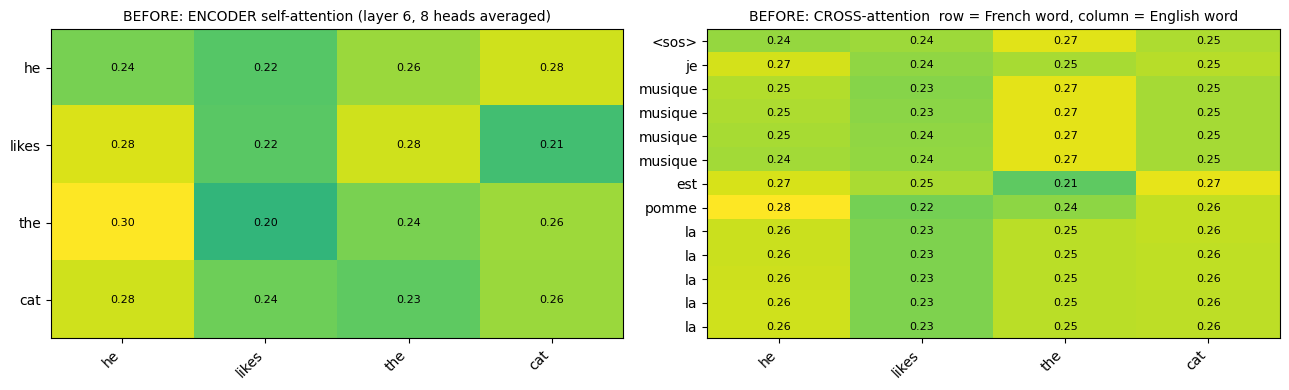

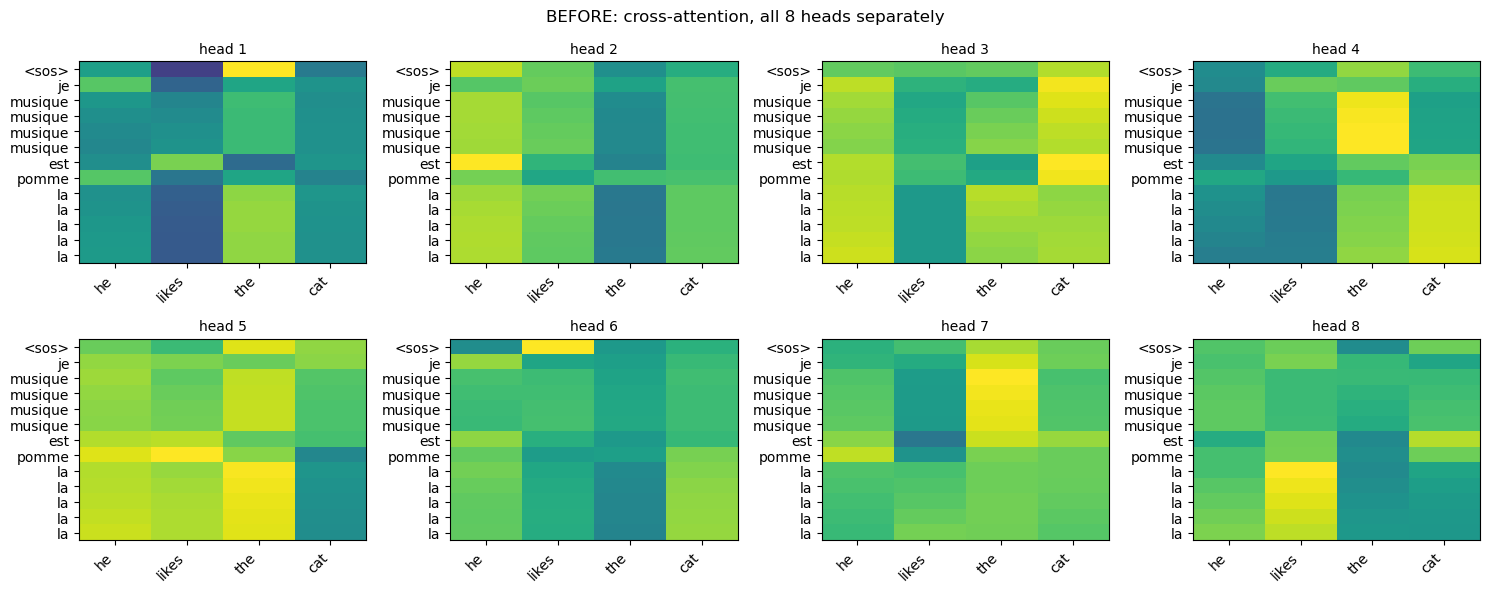

In [15]:
def heat(ax, matrix, rows, cols, title, annotate=True):
    im = ax.imshow(matrix, cmap="viridis", aspect="auto", vmin=0)
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha="right")
    ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows)
    ax.set_title(title, fontsize=10)
    if annotate:
        for i in range(len(rows)):
            for j in range(len(cols)):
                v = float(matrix[i, j])
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if v < float(matrix.max()) * 0.6 else "black")
    return im


@torch.no_grad()
def show_attention(model, sentence, tag):
    model.eval()
    src = torch.tensor([encode(sentence, SRC_STOI)])
    src_words = sentence.split()
    text, ys = translate(model, sentence, return_ids=True)

    # re-run the decoder over what it produced, so last_weights holds those rows
    enc_out, src_mask = model.encode(src)
    model.decode(ys, enc_out, src_mask)
    rows = [TGT_ITOS[i] for i in ys[0].tolist()]          # <sos> + generated words

    enc_w = model.encoders[-1].self_attn.last_weights[0].mean(0)      # avg over heads
    cross = model.decoders[-1].cross_attn.last_weights[0].mean(0)
    heads = model.decoders[-1].cross_attn.last_weights[0]

    print(f"[{tag}]  '{sentence}'  ->  '{text}'")
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    heat(ax[0], enc_w, src_words, src_words,
         f"{tag}: ENCODER self-attention (layer {N_LAYERS}, {N_HEADS} heads averaged)")
    heat(ax[1], cross[:len(rows)], rows, src_words,
         f"{tag}: CROSS-attention  row = French word, column = English word")
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(2, 4, figsize=(15, 6))
    for h, a in enumerate(axes.flat):
        heat(a, heads[h][:len(rows)], rows, src_words, f"head {h+1}", annotate=False)
    fig.suptitle(f"{tag}: cross-attention, all {N_HEADS} heads separately", fontsize=12)
    plt.tight_layout(); plt.show()


show_attention(model, "he likes the cat", "BEFORE")

## 13. Training — the epoch loop

Standard supervised learning. Nothing here is transformer-specific:

- **loss**: cross-entropy over the French vocabulary at *every position*, `ignore_index=0` so `<pad>` doesn't count
- **optimiser**: Adam, learning rate 1e-3
- **batch**: all 67 training pairs in one batch — the dataset is tiny, so every epoch is one gradient step
- at every epoch in `CHECKPOINTS` we also score the **6 held-out sentences the model has never seen**

Watch **four numbers**:

| Number | What it tells you |
|---|---|
| `train loss` | how well the model fits what it was shown |
| `held loss` | how well it fits what it was *not* shown — the honest one |
| `train EM` | exact-match: whole sentences word-for-word correct |
| `held EM` | the same on unseen sentences — real generalisation |

> 🎤 **Say this in class:** Four lines of code do the learning: forward, loss, backward, step. Everything else in this notebook is architecture. Start the cell, then talk while it runs - it takes about 30 seconds.

In [16]:
# a few sentences we will re-translate at every checkpoint, to watch French appear
WATCH = ["he likes the cat", "she is a teacher", "i have a car"]

src, tgt_in, tgt_out = make_batch(TRAIN_PAIRS)
h_src, h_in, h_out = make_batch(HELD_OUT)

opt   = torch.optim.Adam(model.parameters(), lr=LR)
lossf = nn.CrossEntropyLoss(ignore_index=0)     # ignore <pad> positions

history   = []          # (epoch, train_loss) every epoch
evals     = []          # (epoch, train_loss, held_loss, train_em, held_em)
snapshots = []          # (epoch, [translations of WATCH])

t0 = time.time()
print(f"{'epoch':>6} | {'train loss':>10} | {'held loss':>9} | {'train EM':>9} | {'held EM':>7}")
print("-" * 58)

for ep in range(1, EPOCHS + 1):
    model.train()
    logits = model(src, tgt_in)                                         # forward
    loss = lossf(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))
    opt.zero_grad(); loss.backward(); opt.step()                        # backward + step
    history.append((ep, loss.item()))

    if ep in CHECKPOINTS:
        model.eval()
        with torch.no_grad():
            h_logits = model(h_src, h_in)
            held = lossf(h_logits.reshape(-1, h_logits.size(-1)), h_out.reshape(-1)).item()
        tr_em, h_em = exact_match(model, TRAIN_PAIRS), exact_match(model, HELD_OUT)
        evals.append((ep, loss.item(), held, tr_em, h_em))
        snapshots.append((ep, [translate(model, s) for s in WATCH]))
        print(f"{ep:>6} | {loss.item():>10.4f} | {held:>9.4f} | "
              f"{tr_em:>4}/{len(TRAIN_PAIRS)} | {h_em:>3}/{len(HELD_OUT)}")

print("-" * 58)
print(f"trained {EPOCHS} epochs in {time.time() - t0:.1f} seconds on CPU")

 epoch | train loss | held loss |  train EM | held EM
----------------------------------------------------------
     1 |     3.8594 |    3.4102 |    0/67 |   0/6


     2 |     3.3091 |    3.2401 |    0/67 |   0/6
     3 |     3.0969 |    3.1041 |    0/67 |   0/6


     5 |     2.8137 |    2.8215 |    1/67 |   0/6


     8 |     2.3959 |    2.5821 |    3/67 |   0/6


    11 |     2.0896 |    2.3462 |    5/67 |   0/6


    15 |     1.7338 |    2.0242 |   14/67 |   0/6


... (20 outputs left out)

  1200 |     0.0007 |    0.0813 |   67/67 |   5/6


  1300 |     0.0007 |    0.0828 |   67/67 |   5/6


  1400 |     0.0005 |    0.0835 |   67/67 |   5/6


  1500 |     0.0005 |    0.0839 |   67/67 |   5/6
----------------------------------------------------------
trained 1500 epochs in 37.9 seconds on CPU


### Watch the French appear

The same three sentences, re-translated at each checkpoint. Read it top to bottom —
this is the loss curve in words instead of numbers.

Four things to point at:

- **Epochs 1–3 are blank.** The model's very first strategy is to emit `<eos>`
  immediately. It is the single most common token, so predicting it is the cheapest
  possible way to reduce the loss. The model learns to *shut up* before it learns to talk.
- **Epoch 5–8:** fragments appear (`tu le`, `il aime le`) — correct French words,
  no sentence.
- **Epoch 11:** `elle aime le elle aime` — the classic degenerate repetition loop, in
  miniature. It has the shape of a sentence but no idea when to stop.
- **Epochs 15–26:** `i have a car` → `j aime le livre`. Fluent French, right length,
  **wrong verb and wrong noun.** It has learned what a sentence looks like before it
  has learned what the words mean.

By epoch 33 all three are correct, and they never change again — while the loss keeps
falling for another 1,467 epochs.

> 🎤 **Say this in class:** This is the table to slow down on. Point at epoch 11: 'elle aime le elle aime'. Everybody has seen an LLM do exactly this. Now they know what it means - the model has the shape of the language but not the content yet.

In [17]:
print(f"{'epoch':>6} | " + " | ".join(f"{s:<24}" for s in WATCH))
print("-" * 86)
for ep, outs in snapshots:
    print(f"{ep:>6} | " + " | ".join(f"{o:<24}" for o in outs))
print("-" * 86)
print("GOLD   | " + " | ".join(
    f"{dict(TRAIN_PAIRS)[s]:<24}" for s in WATCH))

 epoch | he likes the cat         | she is a teacher         | i have a car            
--------------------------------------------------------------------------------------
     1 |                          |                          |                         
     2 |                          |                          |                         
     3 |                          |                          |                         
     5 | tu le                    | tu                       |                         
     8 | il aime le               | elle aime                | j                       
    11 | il aime le livre         | elle aime le elle aime   | tu es                   
    15 | il aime le chat          | elle est un professeur   | j aime le livre         
    20 | il aime le chat          | elle est un professeur   | j aime le livre         
    26 | il aime le chat          | elle est un professeur   | j aime le livre         
    33 | il aime le chat         

## 14. Reading the loss curve

Three plots, and they tell three different stories.

**Left — the loss curves.** Log scale, because the drop spans four orders of
magnitude. The *train* curve keeps falling forever; the *held-out* curve bottoms out
and then flattens. That gap is **overfitting**, and with 510k parameters fitting 67
sentences it is guaranteed.

**Middle — exact-match accuracy.** Loss is a proxy; this is the thing we actually
want. Note that it is a *staircase*, not a smooth curve — a sentence is wrong until
suddenly every word is right.

**Right — how fast the loss is falling.** The per-epoch drop, smoothed, on a symlog
axis so the dips *below* zero show up too. Almost all the learning is over by epoch
~60; after that the curve is four orders of magnitude lower. Wherever the green line
dips below the grey zero line, the loss got **worse** for a few epochs — Adam
overshooting. Training is not monotonic, and one bad epoch is not a bug.

> 🎤 **Say this in class:** Loss is not accuracy. Loss keeps improving long after accuracy has stopped - the model is getting more CONFIDENT about answers it already had right. That is what a falling train curve over a flat held-out curve means.

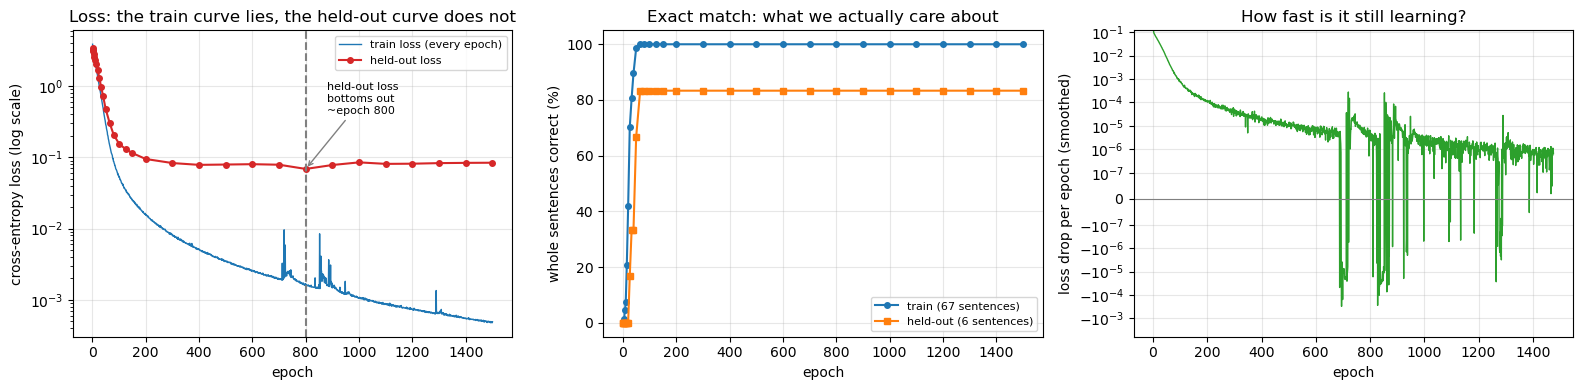

epoch     1: train 3.8594   held 3.4102
epoch   800: held-out loss is at its minimum (0.0686)  <- the point an early-stopping callback would pick
epoch  1500: train 0.0005   held 0.0839   <- train loss is 171x lower than held-out


In [18]:
eps_all, loss_all = zip(*history)
e_ep, e_tr, e_held, e_trem, e_hem = zip(*evals)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# --- 1. loss curves ----------------------------------------------------------
ax[0].plot(eps_all, loss_all, lw=1, color="tab:blue", label="train loss (every epoch)")
ax[0].plot(e_ep, e_held, "o-", ms=4, color="tab:red", label="held-out loss")
best = int(e_ep[e_held.index(min(e_held))])
ax[0].axvline(best, ls="--", color="grey")
ax[0].annotate(f"held-out loss\nbottoms out\n~epoch {best}", xy=(best, min(e_held)),
               xytext=(best * 1.1, min(e_held) * 6), fontsize=8,
               arrowprops=dict(arrowstyle="->", color="grey"))
ax[0].set(yscale="log", xlabel="epoch", ylabel="cross-entropy loss (log scale)",
          title="Loss: the train curve lies, the held-out curve does not")
ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)

# --- 2. exact-match accuracy -------------------------------------------------
ax[1].plot(e_ep, [100 * v / len(TRAIN_PAIRS) for v in e_trem], "o-", ms=4,
           label=f"train ({len(TRAIN_PAIRS)} sentences)")
ax[1].plot(e_ep, [100 * v / len(HELD_OUT) for v in e_hem], "s-", ms=4,
           label=f"held-out ({len(HELD_OUT)} sentences)")
ax[1].set(xlabel="epoch", ylabel="whole sentences correct (%)", ylim=(-5, 105),
          title="Exact match: what we actually care about")
ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)

# --- 3. rate of improvement --------------------------------------------------
import numpy as np
sm = np.convolve(loss_all, np.ones(25) / 25, mode="valid")
ax[2].plot(eps_all[:len(sm)][1:], -np.diff(sm), lw=1, color="tab:green")
ax[2].axhline(0, color="grey", lw=.8)
ax[2].set_yscale("symlog", linthresh=1e-7)   # symlog, so the dips BELOW zero still show
ax[2].set(xlabel="epoch", ylabel="loss drop per epoch (smoothed)",
          title="How fast is it still learning?")
ax[2].grid(alpha=.3)

plt.tight_layout(); plt.show()

print(f"epoch {e_ep[0]:>5}: train {e_tr[0]:.4f}   held {e_held[0]:.4f}")
print(f"epoch {best:>5}: held-out loss is at its minimum ({min(e_held):.4f})"
      "  <- the point an early-stopping callback would pick")
print(f"epoch {e_ep[-1]:>5}: train {e_tr[-1]:.4f}   held {e_held[-1]:.4f}"
      f"   <- train loss is {e_held[-1] / e_tr[-1]:.0f}x lower than held-out")

### The five phases, in plain words

These boundaries are read straight off the run above — your numbers will match,
because the seed is fixed.

| Phase | Epochs | Train loss | What the model is learning | What you see |
|---|---|---|---|---|
| 1. Silence | 1 → 5 | 3.86 → 2.81 | `<eos>` is the cheapest token to predict | empty output |
| 2. Structure | 5 → 20 | 2.81 → 1.36 | sentence length, word order, what French looks like | fragments, then `elle aime le elle aime` |
| 3. Vocabulary | 20 → 50 | 1.36 → 0.29 | which English word maps to which French word | fluent French, wrong verbs and nouns |
| 4. Generalisation | 50 → 400 | 0.29 → 0.005 | the *patterns* behind the pairs, not the pairs | train hits 67/67 at epoch 65, held-out 5/6 at 65 |
| 5. Confidence | 400 → 1500 | 0.005 → 0.0005 | nothing new — just sharpening probabilities | **output never changes again** |

**This is the slide to pause on.** Phase 5 is the one that surprises people. Between
epoch 400 and epoch 1,500:

- train loss fell **10×** (0.0052 → 0.0005)
- held-out loss did **not improve at all** — it drifted from 0.0783 to 0.0839
- every single translation stayed **byte-for-byte identical**

The model was not getting smarter. It was getting *more certain* about things it
already had right. By the last epoch the train loss is **171× lower** than the
held-out loss, and that gap is the entire reason validation sets exist.

One more honest detail. The cell above reports the held-out minimum at epoch 800
(0.0686) — but look at the neighbours: 0.0783 at 400, 0.0791 at 500, 0.0786 at 700,
0.0779 at 900. That "minimum" is **noise in a flat curve**, not a real optimum. This
is exactly how early stopping misleads people on small validation sets: six sentences
cannot resolve a 10% difference in loss.

> 🎤 **Say this in class:** Two lessons, and the second is the one nobody teaches. First: train loss falling while held-out loss is flat means memorisation, not learning. Second: our 'best epoch' is noise. With a 6-sentence validation set you cannot trust the minimum - and plenty of real projects validate on sets that are barely better.

## 15. AFTER training — same code, same architecture, different numbers

Nothing about the model changed except the values inside the weight matrices.

> 🎤 **Say this in class:** Run this right after the BEFORE cell so the contrast lands. Same class definitions, same forward pass, same 510,316 parameters. Different numbers in the matrices. That is all training is.

In [19]:
show_translations(model, "AFTER TRAINING  (the architecture never changed -- only the weights)")

AFTER TRAINING  (the architecture never changed -- only the weights)
  EN: i am a student      | MODEL: je suis un etudiant       | GOLD: je suis un etudiant
  EN: i am a teacher      | MODEL: je suis un professeur     | GOLD: je suis un professeur
  EN: you are a student   | MODEL: tu es un etudiant         | GOLD: tu es un etudiant
  EN: you are a teacher   | MODEL: tu es un professeur       | GOLD: tu es un professeur
  EN: he is a student     | MODEL: il est un etudiant        | GOLD: il est un etudiant
  EN: he is a teacher     | MODEL: il est un professeur      | GOLD: il est un professeur
  ----------------------------------------------------------------------------------
  EN: she likes tea       | MODEL: elle aime le the          | GOLD: elle aime le the   <-- NEVER TRAINED ON
  EN: he has a dog        | MODEL: il a un chien             | GOLD: il a un chien   <-- NEVER TRAINED ON
  EN: she eats the apple  | MODEL: elle mange la pomme       | GOLD: elle mange la pomme   <-- NE


  exact match: train 67/67   held-out 5/6


[AFTER]  'he likes the cat'  ->  'il aime le chat'


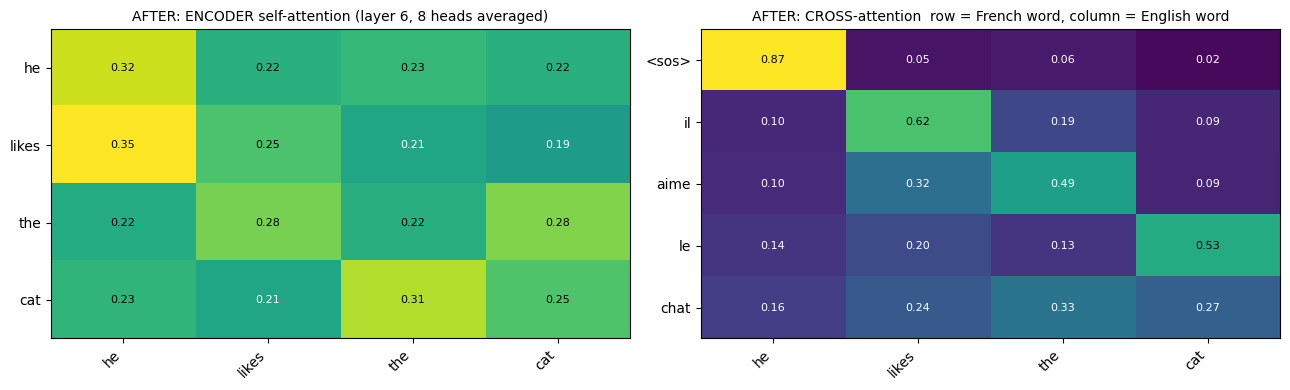

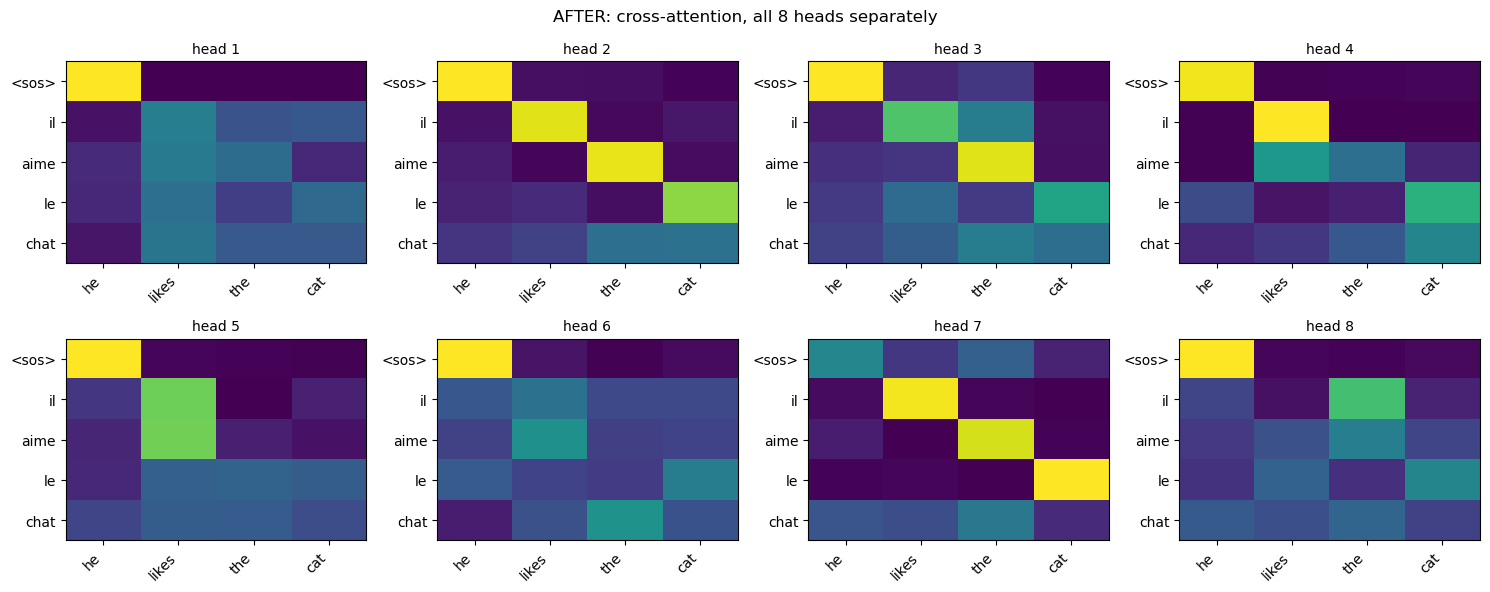

In [20]:
show_attention(model, "he likes the cat", "AFTER")

Now read the **cross-attention** panel row by row. Every row has collapsed from the
flat 0.25s into one bright cell — the model has learned exactly which English word to
look at. Compare it with the BEFORE panel above; same model, same code.

**But notice the alignment is offset by one row:**

| row (French word it is sitting on) | brightest column | because it is about to write |
|---|---|---|
| `<sos>` | **he** | `il` |
| `il` | **likes** | `aime` |
| `aime` | **the** | `le` |
| `le` | **cat** | `chat` |
| `chat` | *diffuse* | `<eos>` — nothing left to look at |

That is not a bug, and it is worth a minute in class. The decoder's output at position
*t* is used to predict the word at position *t+1*. So while it is sitting on `il`, it
is already looking at the English word it is **about to** translate. Shift your eye one
row up and the diagonal is perfect.

Nobody labelled those alignments. We only ever showed the model whole sentence pairs —
the word-to-word mapping is an emergent side-effect of minimising next-word loss.

And the 8 heads no longer look alike: they have split the job between them.

> 🎤 **Say this in class:** This is the picture to leave on screen. Two points: nobody labelled the word alignments, they emerged; and the one-row offset is the whole 'next-token prediction' idea made visible. The model is always looking one step ahead of where it is standing.

## 16. Generalisation — and the one it gets wrong

The interesting cell in the whole notebook. Six sentences the model has **never seen**.
Every individual word was in training; only the combination is new.

Look at which one fails and ask *why* before reading on.

In [21]:
print("HELD-OUT SET -- never trained on")
print("=" * 86)
ok = 0
for eng, gold in HELD_OUT:
    got = translate(model, eng)
    mark = "OK  " if got == gold else "WRONG"
    ok += got == gold
    print(f"  [{mark}] {eng:<22} -> {got:<26} gold: {gold}")
print("=" * 86)
print(f"  {ok}/{len(HELD_OUT)} exact match on sentences the model has never seen")

HELD-OUT SET -- never trained on
  [OK  ] she likes tea          -> elle aime le the           gold: elle aime le the
  [OK  ] he has a dog           -> il a un chien              gold: il a un chien
  [OK  ] she eats the apple     -> elle mange la pomme        gold: elle mange la pomme
  [OK  ] you like coffee        -> tu aimes le cafe           gold: tu aimes le cafe
  [OK  ] the cat is tired       -> le chat est fatigue        gold: le chat est fatigue
  [WRONG] you drink the water    -> tu manges le pain          gold: tu bois l eau
  5/6 exact match on sentences the model has never seen


### Why that one fails — and it is not a bug

Look at how much evidence the training set gives for each held-out pattern:

| Held-out sentence | Evidence in training | Result |
|---|---|---|
| `she likes tea` | `she likes` 5×, `le the` 2× | ✅ |
| `he has a dog` | `he has` 3×, `un chien` 2× | ✅ |
| `she eats the apple` | `la pomme` 3×, `elle` 12×, `mange` 3× | ✅ |
| `you like coffee` | `tu aimes` 6×, `le cafe` 3× | ✅ |
| `the cat is tired` | `le chat` 5×, `est fatigue` 2× | ✅ |
| `you drink the water` | **`drink` 2× in all, and `tu bois` never** | ❌ |

The model learned `je bois` and `il boit`, but it never saw the second-person form of
*any* drinking verb. Two examples is not enough evidence for a pattern, so it falls
back on the nearest high-frequency structure it knows: it answers a sentence about
**eating** instead. Correct French, correct person, correct sentence shape — and
completely the wrong verb and object. It reached for the `tu + verb + food` pattern
it has the most evidence for (`tu manges ...` appears twice; `tu bois ...` never).

**That is the entire story of LLM scaling in one row of a table.** Patterns supported
by many examples generalise. Patterns supported by two examples do not. The fix is not
a cleverer architecture; the fix is more data.

> 🎤 **Say this in class:** This is the most honest cell in the notebook. Do not skip the failure. 'you drink the water' fails because 'tu bois' never appeared, and nothing in the architecture can invent it. When people ask why GPT needed the whole internet - this is why, scaled up.

## 17. What happened to the embeddings?

The embedding table started as random noise. Training pulled words that behave alike
towards each other. Compare cosine similarity between English word vectors before and
after — pronouns drift together, nouns drift together.

(With 67 sentences don't expect a textbook picture; expect a *nudge* in the right
direction.)

> 🎤 **Say this in class:** This answers 'where is the meaning stored?'. Partly here, in the embedding table, and partly in the attention weight matrices. There is no dictionary anywhere in this model.

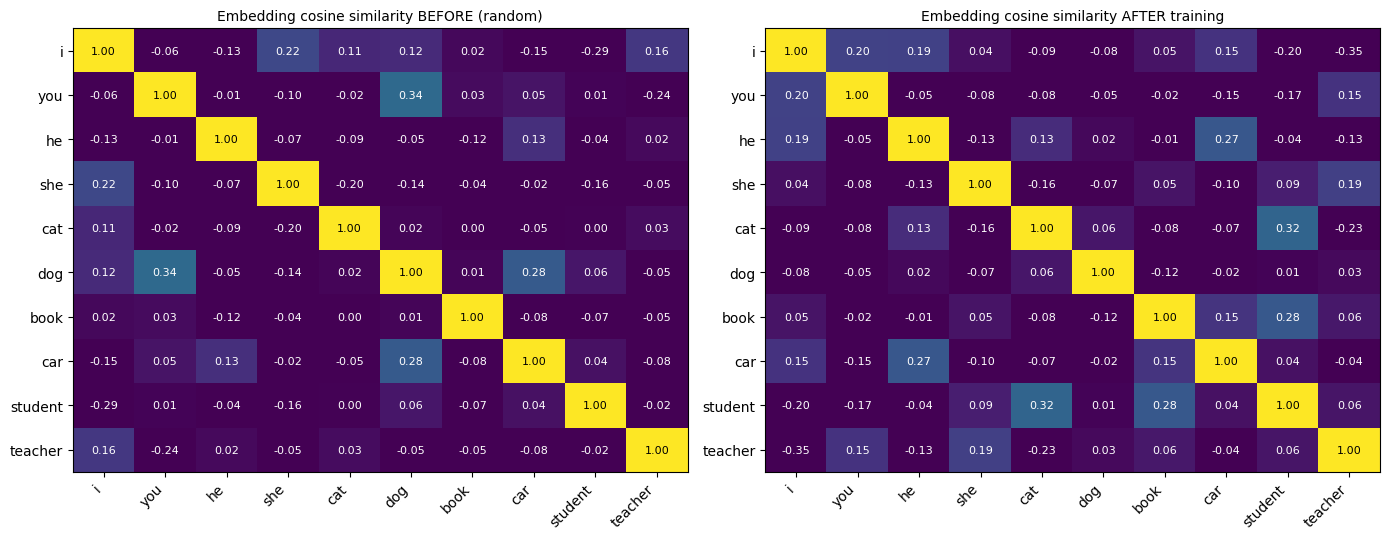

Look at the pronoun block (i / you / he / she) versus the noun block.
Words that play the same grammatical role have moved closer together.


In [22]:
fresh = Transformer()                       # an untrained twin, for comparison


def cos_sim_matrix(emb_weight, words, stoi):
    v = emb_weight[[stoi[w] for w in words]]
    v = v / v.norm(dim=-1, keepdim=True)
    return (v @ v.T).detach()


words = ["i", "you", "he", "she", "cat", "dog", "book", "car", "student", "teacher"]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
heat(ax[0], cos_sim_matrix(fresh.src_emb.weight, words, SRC_STOI), words, words,
     "Embedding cosine similarity BEFORE (random)")
heat(ax[1], cos_sim_matrix(model.src_emb.weight, words, SRC_STOI), words, words,
     "Embedding cosine similarity AFTER training")
plt.tight_layout(); plt.show()

print("Look at the pronoun block (i / you / he / she) versus the noun block.")
print("Words that play the same grammatical role have moved closer together.")

## 18. Try it yourself

Type any sentence built from the English vocabulary printed in section 1.

Unseen **combinations** often work. Unseen **words** cannot possibly work — there is no
trained row for them in the embedding table.

> 🎤 **Say this in class:** Take a sentence request from the room, as long as every word is in the vocabulary. When someone suggests a word that is not there, use it: explain that there is no row for it in the embedding table, which is exactly what a tokenizer error looks like in a real LLM.

In [23]:
TRY = [
    "she is a student",      # seen
    "he is tired",           # seen
    "she has a dog",         # NEW combination
    "you read the car",      # NEW and semantically silly -- it will still answer
    "the dog is happy",      # NEW combination
    "i like the apple",      # NEW combination
]
for s in TRY:
    known = all(w in SRC_STOI for w in s.split())
    seen = s in dict(TRAIN_PAIRS)
    tag = "trained" if seen else "NEW combination"
    print(f"  {s:<22} -> {translate(model, s):<28} ({tag})" if known
          else f"  {s:<22} -> OUT OF VOCABULARY")

# 'apple' appears in training only as the object of EAT, never of LIKE.
# Read the model's actual answer rather than quoting one from a previous run.
apple = translate(model, "i like the apple")
seen_after_jaime = sorted({p[1].split("j aime", 1)[1].strip()
                           for p in TRAIN_PAIRS if p[1].startswith("j aime")})
print(f"\n'i like the apple' -> '{apple}'")
print(f"  'apple' / 'pomme' only ever appeared after EAT, never after LIKE.")
print(f"  Objects the model HAS seen after 'j aime': {seen_after_jaime}")
print(f"  So it substitutes one of those. Same failure as 'you drink the water'.")
print()
print("And notice it ALWAYS answers. There is no 'I don't know' anywhere in this")
print("architecture -- the softmax has to put its mass somewhere. Hallucination is not")
print("a bug that was added later; it is what this loop does by construction.")

  she is a student       -> elle est un etudiant         (trained)
  he is tired            -> il est fatigue               (trained)


  she has a dog          -> elle a un chien              (NEW combination)
  you read the car       -> tu lis la voiture            (NEW combination)
  the dog is happy       -> le chien est content         (NEW combination)
  i like the apple       -> j aime la musique            (NEW combination)

'i like the apple' -> 'j aime la musique'
  'apple' / 'pomme' only ever appeared after EAT, never after LIKE.
  Objects the model HAS seen after 'j aime': ['la musique', 'la voiture', 'le cafe', 'le chat', 'le chien', 'le livre', 'le the']
  So it substitutes one of those. Same failure as 'you drink the water'.

And notice it ALWAYS answers. There is no 'I don't know' anywhere in this
architecture -- the softmax has to put its mass somewhere. Hallucination is not
a bug that was added later; it is what this loop does by construction.


## 19. Live experiments for the class

Change one thing in the hyperparameter cell (section 0), then **Restart & Run All**
and see what breaks. Each one takes about 30 seconds.

| Experiment | Change | What to watch |
|---|---|---|
| Does depth matter? | `N_LAYERS = 1` | loss still drops — 6 layers is overkill for 67 sentences |
| Do we need 8 heads? | `N_HEADS = 1` | still learns; the heat map loses its specialisation |
| Undertrain | `EPOCHS = 60` | French-shaped nonsense: right structure, wrong words |
| Overtrain | `EPOCHS = 5000` | train loss → 0, held-out loss *rises*. Textbook overfitting |
| Kill word order | delete `self.pos(...)` in `encode`/`decode` | "i like the cat" and "the cat likes i" become identical to the encoder |
| Remove the √d_k | drop `/ math.sqrt(d_k)` in `attention` | scores blow up, softmax saturates, training slows badly |
| Remove the causal mask | pass `pad_mask(tgt_in)` instead of `causal_mask` | loss crashes to ~0 instantly — it is reading the answer — and generation is garbage |
| Break the residuals | drop the `x +` in a layer's `forward` | with 6 layers, training barely moves |
| Starve it | train on `TRAIN_PAIRS[:12]` | held-out accuracy collapses. Data, not architecture |

### The four sentences to leave them with

1. An LLM is this notebook's **decoder stack**, scaled: more layers, more heads, wider `d_model`, and internet-scale data instead of 67 sentences.
2. Attention is a **soft, learned lookup table** — Q asks, K advertises, V delivers.
3. The architecture was **identical** before and after training. Every bit of intelligence you watched appear lives in the numbers inside `W_q`, `W_k`, `W_v` and the embeddings.
4. Where it failed, it failed for lack of **evidence**, not lack of architecture. That is why the answer to "make it better" has been "more data" for eight years running.